<a href="https://colab.research.google.com/github/mihailescuiacob-lgtm/cb2330-PRO1_Pair-21/blob/main/PRO1_Pair_21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CB2330 PRO1_ Pair 21






# Project Card

**The paper**: Ståhl, P. L. et al. (2016) Visualization and analysis of gene expression in tissue sections by spatial transcriptomics. Science 353(6294):78-82.
https://doi.org/10.1126/science.aaf2403

**The data object**: Figure S6 from the paper: Average number of unique transcripts per area (diameter approximately 100 μm) for single-molecule fluorescent in-situ hybridization (smFISH) and per feature for spatial transcriptomics (ST). These values were compared for 3 different genes across 4 different tissue layers. The values were digitized & rounded from the means of the figure.

**The random variable chosen**: Transcripts of a gene detected by ST, in one feature of a tissue layer (ki). It is a non-negative integer that varies between features and experiments, because capturing an mRNA is random.

**What the paper does**: The paper describes the development of the ST technology, a technology used to quantify mRNA transcripts present in a tissue, while preserving their postion in a tissue. The authors developed a spatially barcoded array which was split into 1007 "features". Feature represent areas of diameter 100 μm and a center-to-center distance of 200 μm. Features were spread over an area of 6.2 x 6.6 mm. Each feature holds ~200 million oligonucleotides probes, each containing a specific spatial barcode and a unique molecular identifier (UMI).

Tissue sections were placed onto this array, fixed, stained with haematoxylin and eosin (H&E) and imaged to visualize the section's histology. Tissues were then permeabilised and mRNA molecules from the tissue could then bind to the probes. cDNA was synthesized with reverse transcription, followed by enzymatic removal of the tissue. cDNA molecules were then released from the array, amplified and sequenced. The spatial barcode sequence can be used to determine the feature where the mRNA was present.

The sensitivity was determined by comparing the average number of transcripts detected by ST in a feature to the average number of transcripts detected by smFISH (near 100% sensitivity), claiming that "ST detects 6.9 ± 1.5% of smFISH transcript". For the comparison, the authors used mouse brain tissues from the olfactory bulb divided into 4 different layers: glomerular layer (GL), mitral cell layer (MCL), granular cell layer (GCL) and outer plexiform layer (OPL), and compared the transcripts from 3 different genes in those layers: Fabp7, Penk and Slc6a11.

**The generative model proposed**: Our model attempts to compare the amount of transcripts captured by ST in comparison to smFISH. From a total of N transcripts (determined by smFISH), k transcripts are captured by ST, each with an independent probability of being captured, theta (θ). This follows a Poisson distribution: ki ~ Poisson(λi = θ * N).

**Parameters and assumptions**:
Assumptions:
1. smFISH captures 100% of the transcripts present
2. all transcripts have the same probability (θ) of being captured, independent of the layer they are present in
3. mRNAs do not move between features (the signal diffusion reported was way lower than distance between features)
4. mRNA capturing follows a Poisson distribution

**The forward simulation**: Uses a random number generator to obtain a number between [0,1), and thereby simulate mRNA transcripts being captured by ST, models it using a Poisson distribution, and calculates the mean and standard deviation of the data produced. Taking the sensitivity declared in the paper, we simulated the amount of transcripts captured by ST, and obtained a mean value of 640.6, (published data ~ 412)

**The parameterization/fitting**:
Our model takes the parameter theta, which represents the probability of capturing an mRNA molecule by ST. For each gene/layer, the count of transcripts is represented by a poisson distribution, using the number of transcripts captured by smFISH (N) as 100% of the transcripts present.


First, we created a random number generator that draws a random number r, between [0,1), which is then used to obtain the number of captured mRNA transcripts by ST, following a Poisson distribution. For this we used N as the number of transcripts captured by smFISH, and the sensitivity = 0.069 as provided by the paper. We also provide a plot for the visualisation of the frequency of mRNA transcripts captured by ST using these parameters. This was the forward run.


For the backwards run, we attempted to use our model backwards in order to calculate our own value of theta (sensitivity), and compare it to that of the paper. To do this, we attempted to find the value that maximises the observed ST counts (equivalent to the minimum value of the negative log likelihood). The value of theta we obtained was 0.044.


Finally we calculated the uncertainty of theta, which was found to be in the range 0.042-0.047 using the likelihood interval method and 0.041-0.052 using the bootstrap method.

**What/if the model adds to the paper**:
Our model provides a mechanistic interpretation of the sensitivity reported by the paper. It models the detection of each transcript as a random capture event with probability theta, as opposed to simply an experimental observation.
This allows us to:
1. Measure the probability of a single capture from the figure.
2. Repeat the experiment multiple times and calculate the variation between sensitivity across trials.

**Model limitations/how it breaks**:
There are some limitations that come with this model.
1. The forward model is created assuming a single sensitivity across all captures (0.069). This may not reflect what is really happening, as capturing a transcript could vary across gene layers, genes, local properties of the tissue, and more.
2. It is assumed that transcript capturing is independent, ignoring the possibility of one transcript capturing influencing the capture of another.
3. The smFISH is assumed to capture 100% of transcripts, which may not reflect a true scenario. The paper itself states that smFISH is only able to capture near 100% of transcripts.
4. The ability of ST to capture mRNA is only represented by one parameter: theta. However, ST is a complicated process that includes probes-mRNA binding, reverse transcription, cDNA processing, etc. As a result, the model does not identify which exact step of the procedure is responsible for the mRNA being captured.
5. There is a probability that during breakdown of the tissue to isolate the mRNA molecules that have been captured, some mRNA also degrades. This may contribute to the low sensitivity of ST measured. This is more of a limitation from the paper itself, however it directly influences the construction of our model.  

## Import data and math

In [1]:
import math
import matplotlib.pyplot as plt

In [2]:
sensitivity = 0.069

# Fig.S6:
#              Gene        Layer         transcripts ST  transcript from smFISH
conditions = [("Fabp7",    "GL",         58,             1555),
              ("Penk",     "GL",         8,                55),
              ("Slc6a11",  "GL",         55,             1132),
              ("Fabp7",    "OPL",        27,              712),
              ("Penk",     "OPL",        5,                21),
              ("Slc6a11",  "OPL",        47,             1063),
              ("Fabp7",    "MCL",        26,              636),
              ("Penk",     "MCL",        25,              213),
              ("Slc6a11",  "MCL",        40,              874),
              ("Fabp7",    "GCL",        24,              696),
              ("Penk",     "GCL",        63,             1559),
              ("Slc6a11",  "GCL",        34,              752),
              ]

#k: total transcript captured by ST, N: transcripts present (as determined by smFISH)
ks = [c[2] for c in conditions]
Ns = [c[3] for c in conditions]
A = len(Ns)

print ("ST Count:",ks)
print ("smFISH Counts:", Ns)
print ("Number of areas/features:", A)

ST Count: [58, 8, 55, 27, 5, 47, 26, 25, 40, 24, 63, 34]
smFISH Counts: [1555, 55, 1132, 712, 21, 1063, 636, 213, 874, 696, 1559, 752]
Number of areas/features: 12


In [3]:
#count by ST
k_total = 0
for k in ks:
  k_total = k_total + k

#counts by smFISH
N_total = 0
for n in Ns:
  N_total = N_total + n

ratio = k_total/N_total

print("Transcripts by ST:", k_total)
print("Transcripts by smFISH:", N_total)
print("Ratio ST/smFISH (theta):", ratio)

Transcripts by ST: 412
Transcripts by smFISH: 9268
Ratio ST/smFISH (theta): 0.044454035390591284


In [4]:
# Random number generator
A_LCG = 1664525
C_LCG = 1013904223
M_LCG = 2 ** 32     #Multiplier & Increment from Numerical Recipes

def lcg(state, a, c, m):
    """The next state of a linear congruential generator: s_{i+1} = (a * s_i + c) mod m."""
    return (a * state + c) % m

def factorial(x):
  total = 1
  for k in range (1, x+1):
    total = total * k
  return total

def poisson(x, theta):
    """p(x | theta) = theta^x e^(-theta) / x!  the probability of x colonies at rate theta."""
    p = ((theta ** x) * math.exp(-theta))/factorial(x)
    return p

Ensure draw is random

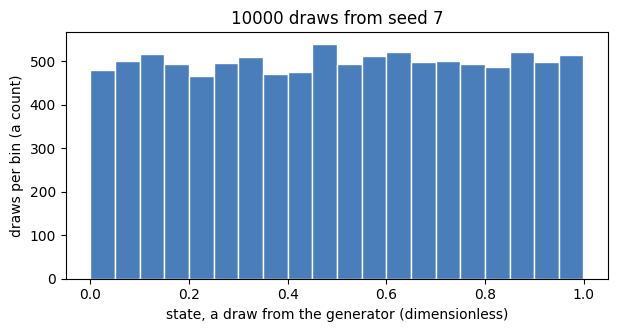

In [5]:
state = 7
rs = [0.0] * 10000
for i in range(10000):
    state = lcg(state, A_LCG, C_LCG, M_LCG)
    rs[i] = state/M_LCG

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(rs, bins=20, color="#4a7ebb", edgecolor="white")
ax.set_xlabel("state, a draw from the generator (dimensionless)")
ax.set_ylabel("draws per bin (a count)")
ax.set_title("10000 draws from seed 7")
plt.show()

## Poisson_ count the amount of transcripts

In [6]:
def capture_poisson(lamda, state):
  state = lcg(state, A_LCG, C_LCG, M_LCG)
  r = state/M_LCG
  stair = poisson(0, lamda)
  count = 0
  while r > stair:
    count = count + 1
    stair = stair + poisson (count, lamda)
  return count, state

def experiment(transcr_list, theta, state): #transcr_list: transcripts in layer
  total = 0
  for n in transcr_list:
    k, state = capture_poisson((theta * n),state)
    total = total + k
  return total, state

Run experiment once





In [7]:
state = 7
total, state = experiment(Ns, sensitivity, state)
print("Poisson model: transcripts captured with ST from", N_total, "transcripts =", total)
print("State = ", state)
print("")
print("Actual no. of transcripts captured with ST:", k_total)

Poisson model: transcripts captured with ST from 9268 transcripts = 670
State =  2281704755

Actual no. of transcripts captured with ST: 412


Run experiment multiple times - Foward run

In [8]:
REPLICATES = 1000
results = [0.0] * REPLICATES
state = 7
for r in range(len(results)):
  results[r], state = experiment(Ns, sensitivity, state)
  r = r + 1

PLOT

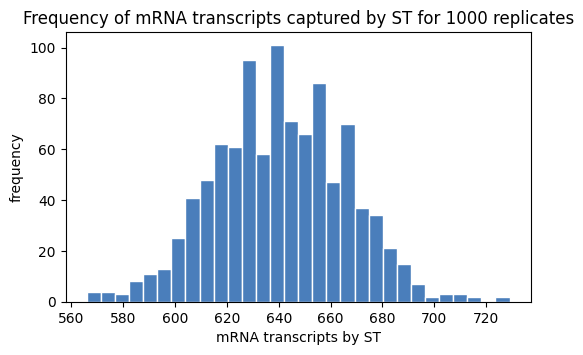

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(results, bins=30, color="#4a7ebb", edgecolor="white")
ax.set_xlabel("mRNA transcripts by ST")
ax.set_ylabel("frequency")
ax.set_title("Frequency of mRNA transcripts captured by ST for 1000 replicates")
plt.show()

Mean, variance and standard deviation functions

In [10]:
def expected_mean(values):
  total = 0.0
  for x in values:
    total = total + x * (1/len(values))
  return total

def variance(values):
  mu = expected_mean(values)
  total = 0.0
  for i in values:
    total = total + ((i-mu) ** 2 * (1/len(values)))
  return total

def standard_deviation(values):
  return((variance(values)**(1/2)))

Applying functions to data - Forward run

In [11]:
print("Total trasncript count from given data:", k_total)
print("")
print(f"Mean of generated data: {expected_mean(results):.1f}")
print(f"S.d of generated data: {standard_deviation(results):.1f}")

Total trasncript count from given data: 412

Mean of generated data: 640.6
S.d of generated data: 25.4


## Backwards Run

In [12]:
# Sweep
def nll(theta):
    """NLL(theta) = - the sum over dishes of log p(x_i | theta)."""
    total = 0.0
    for i in range(len(Ns)):
      lam = Ns[i] * theta
      total = total + lam - ks[i] * math.log(lam) + math.log(factorial(ks[i]))
    return total

def position_of_min(values):
    """The index of the smallest entry: the position, not the value."""
    best = 0
    for j in range(len(values)):
        if values[j] < values[best]:
            best = j
    return best


GRID = 2001
G_LO, G_HI = 0.001, 0.15
dtheta = (G_HI - G_LO) / (GRID-1)

thetas_back = [0.0] * GRID
scores = [0.0] * GRID


for j in range(GRID):
  thetas_back[j] = G_LO + dtheta * j
  scores[j] = nll(thetas_back[j])

j_hat = position_of_min(scores)
theta_hat_sweep = thetas_back[j_hat]

#print(thetas_back)

print("theta_hat (grid)      =", round(theta_hat_sweep, 5))
print("theta_hat (analytic)  =", round(sum(ks) / sum(Ns), 5))   # Poisson MLE = sum(k)/sum(N)

theta_hat (grid)      = 0.04443
theta_hat (analytic)  = 0.04445


In [13]:
# Poisson Slope

def slope_at(score, theta, h):
  return (score(theta + h) - score(theta - h)) / (2 * h)

def descend_adaptive(score, theta, alpha, h=1e-6, tol=1e-3, max_steps=200):
    path = [theta]
    for step in range(max_steps):
        slope = slope_at(score, theta, h)
        if abs(slope) < tol:
            return path
        theta_try = theta - alpha * slope
        if score(theta_try) > score(theta):
            alpha = alpha / 2
        else:
            theta = theta_try
            alpha = alpha * 1.2
        path.append(theta)
    print("warning: did not converge in", max_steps, "steps")
    return path

path = descend_adaptive(nll, theta=0.069, alpha=1e-5)
theta_hat = path[-1]
print("theta_hat (descent) :", round(theta_hat, 6), "in", len(path) - 1, "steps")
print("theta_hat (analytic):", round(sum(ks) / sum(Ns), 6))
print("slope at theta_hat  :", round(slope_at(nll, theta_hat, 1e-6), 5))

theta_hat (descent) : 0.044454 in 21 steps
theta_hat (analytic): 0.044454
slope at theta_hat  : 1e-05


## Uncertainty_Likelihood Interval

In [14]:
# Likelihood interval

low = theta_hat_sweep
high = theta_hat_sweep

for j in range(GRID):
  if scores[j] <= scores[j_hat] + 0.5:
    if thetas_back[j] < low:
      low = thetas_back[j]
    if thetas_back[j] > high:
      high = thetas_back[j]

print("likelihood interval for theta:", round(low,3), "to", round(high,3), "half-width:", (high-low)/2)

likelihood interval for theta: 0.042 to 0.047 half-width: 0.0021604999999999992


In [15]:
# Curvature error bars
# Near the minimum, the curve is close to a parabola - we measure how sharply the curve ends at the bottom.
# A parabola's width is set by its curviture, c.
# Assumption: a curve that isn't a parabola near its minimum, or isn't smooth, gives a number that isn't a width
# We will use lamda, to represent the transcripts
#lamda_hat_sweep = theta_hat_sweep * N_total

h = theta_hat_sweep/1000
curvature = (nll(theta_hat_sweep + h) - 2 * nll(theta_hat_sweep) + nll(theta_hat_sweep - h)) / h ** 2
sigma_curv = 1 / curvature ** 0.5

print("curvature:", round(curvature,3))
print("error bar from curvature:", round(sigma_curv,4))
print("sqrt(theta_hat_sweep / A) =", round(((theta_hat_sweep * N_total)/ A) ** 0.5, 3))

curvature: 208677.866
error bar from curvature: 0.0022
sqrt(theta_hat_sweep / A) = 5.858


Bootstrap

In [16]:
def uniforms(k, seed):
    """A list of k numbers on [0, 1): the generator run k times from the seed, each state divided by m."""
    out = [0.0] * k
    state = seed
    for i in range(k):
        state = lcg(state, A_LCG, C_LCG, M_LCG)
        out[i] = state / M_LCG
    return out


def choose(r, probs):
    """The outcome k whose slice of [0, 1) contains r, the slices laid end to end in order. Returns k as a position in probs, from 0."""
    running = 0.0
    for k in range(len(probs)):
        running = running + probs[k]
        if r < running:
            return k
    return len(probs) - 1

B = 2000                                          # resamples
SEED = 8
rs = uniforms(B * A, SEED)                        # every draw the bootstrap needs, 12 per resample
equal = [1 / A] * A                               # p(x*_i = x_j | x) = 1/N for every j


In [17]:
boot_estimates = [0.0] * B
for b in range(B):
    k_sum = 0
    N_sum = 0
    for i in range(A):
        j = choose(rs[b * A + i], equal)     # pick one gene–layer pair at random
        k_sum = k_sum + ks[j]                # keep its ST count AND its smFISH count together
        N_sum = N_sum + Ns[j]
    boot_estimates[b] = k_sum / N_sum        # refit: MLE on the resample
boot_estimates.sort()
print(f"bootstrap mean : {expected_mean(boot_estimates):.4f}")
print(f"bootstrap SD   : {standard_deviation(boot_estimates):.4f}")
print(f"95% interval   : {boot_estimates[int(0.025*B)]:.4f} to {boot_estimates[int(0.975*B)]:.4f}")

bootstrap mean : 0.0448
bootstrap SD   : 0.0028
95% interval   : 0.0406 to 0.0515


Plot

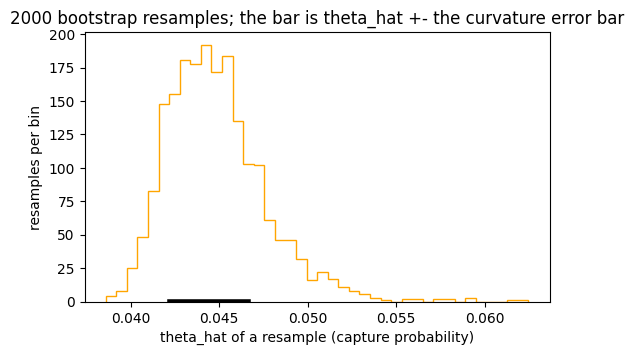

In [18]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(boot_estimates, bins=40, color="orange", histtype="step")
ax.plot([theta_hat_sweep - sigma_curv, theta_hat_sweep + sigma_curv], [0, 0], color="black", linewidth=4)
ax.set_xlabel("theta_hat of a resample (capture probability)")
ax.set_ylabel("resamples per bin")
ax.set_title("2000 bootstrap resamples; the bar is theta_hat +- the curvature error bar")
plt.show()